# **ANALISI** FIT TRADIZIONALE con multi-start Monte Carlo


---

SNR v RMSE

File CSV trovati ed elaborabili: 207
Riepilogo completato: 207 configurazioni analizzate.
Valori di M presenti nei dati: [1, 5, 10, 20, 40]


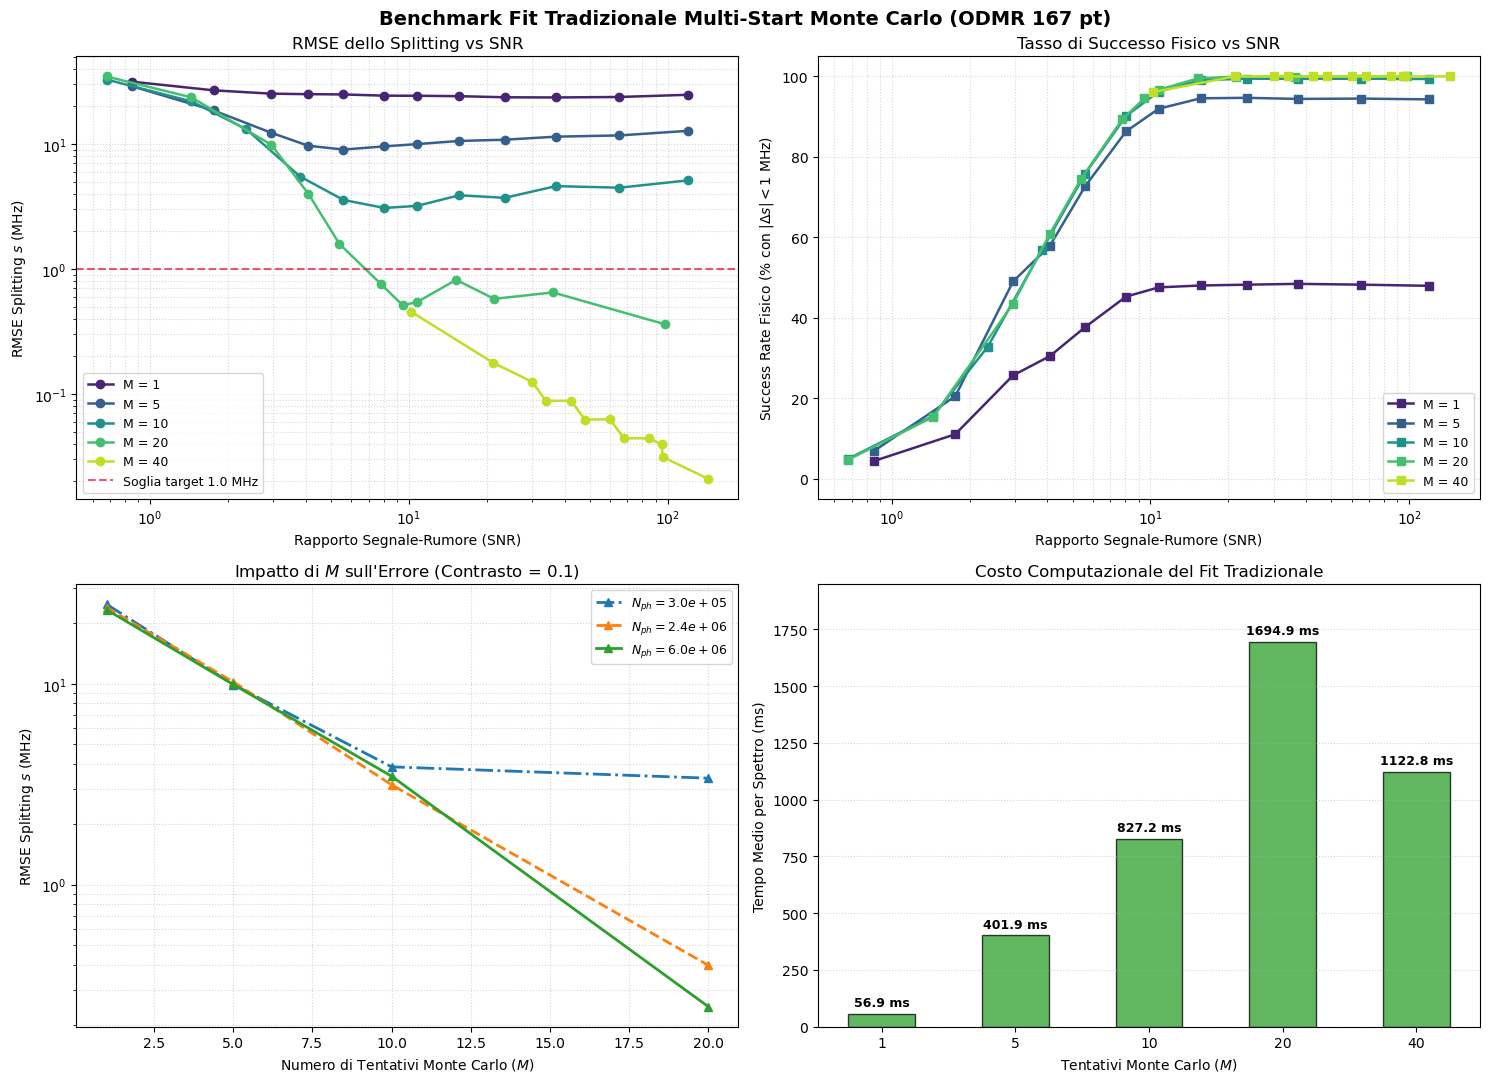

In [1]:
import glob
import os
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# =========================================================================
# 1. SCANSIONE DEI CSV E AGGREGAZIONE METRICHE
# =========================================================================
base_benchmarks_dir = os.path.abspath("../benchmarks/10k")
csv_files = glob.glob(
    os.path.join(base_benchmarks_dir, "**", "*.csv"), recursive=True
)

print(f"File CSV trovati ed elaborabili: {len(csv_files)}")

K_points = 167  # Numero canali di sweep
delta_sweep_mhz = 200.0  # Finestra fisica [2.75, 2.95] GHz

records = []

for filepath in csv_files:
  # Estrazione parametri dal path
  match_c = re.search(r"contrast=([\d\.]+)", filepath)
  match_m = re.search(r"mc_trials=(\d+)", filepath)
  match_n = re.search(r"Nph(\d+)", filepath)

  if not (match_c and match_m and match_n):
    continue

  c_val = float(match_c.group(1))
  m_val = int(match_m.group(1))
  n_ph = float(match_n.group(1))

  # Calcolo analitico SNR di singolo canale
  snr_val = c_val * np.sqrt(n_ph / K_points)

  # Lettura del CSV saltando i metadati
  try:
    df = pd.read_csv(filepath, comment="#")
  except Exception:
    continue

  n_total = len(df)
  if n_total == 0:
    continue

  # Fit che non sono esplosi in NaN
  valid = df[df["converged"] == 1]
  n_conv = len(valid)

  if n_conv > 0:
    # Errori assoluti in MHz
    err_c_mhz = valid["err_c_norm"] * delta_sweep_mhz
    err_s_mhz = valid["err_s_norm"] * delta_sweep_mhz

    rmse_c_mhz = np.sqrt(np.mean(err_c_mhz**2))
    rmse_s_mhz = np.sqrt(np.mean(err_s_mhz**2))
    mae_c_mhz = np.mean(err_c_mhz)
    mae_s_mhz = np.mean(err_s_mhz)

    # Tasso di successo fisico: quanti fit hanno centrato lo splitting con errore < 1 MHz
    n_phys_success = np.sum(err_s_mhz < 1.0)
    phys_success_rate = (n_phys_success / n_total) * 100.0
    conv_rate = (n_conv / n_total) * 100.0
    mean_time_ms = valid["fit_time_sec"].mean() * 1e3
  else:
    rmse_c_mhz, rmse_s_mhz = np.nan, np.nan
    mae_c_mhz, mae_s_mhz = np.nan, np.nan
    phys_success_rate, conv_rate = 0.0, 0.0
    mean_time_ms = np.nan

  records.append({
      "contrast": c_val,
      "mc_trials": m_val,
      "n_photons": n_ph,
      "snr": snr_val,
      "rmse_c_mhz": rmse_c_mhz,
      "rmse_s_mhz": rmse_s_mhz,
      "mae_c_mhz": mae_c_mhz,
      "mae_s_mhz": mae_s_mhz,
      "conv_rate": conv_rate,
      "phys_success_rate": phys_success_rate,
      "time_per_fit_ms": mean_time_ms,
  })

df_summary = pd.DataFrame(records)
print(f"Riepilogo completato: {len(df_summary)} configurazioni analizzate.")
print(f"Valori di M presenti nei dati: {sorted(df_summary['mc_trials'].unique())}")

# =========================================================================
# 2. GENERAZIONE DEI GRAFICI COMPARATIVI
# =========================================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
fig.suptitle(
    "Benchmark Fit Tradizionale Multi-Start Monte Carlo (ODMR 167 pt)",
    fontsize=14,
    fontweight="bold",
    y=0.98,
)

# Palette e marker per i vari M presenti
available_m = sorted(df_summary["mc_trials"].unique())
colors = plt.cm.viridis(np.linspace(0.1, 0.9, len(available_m)))
m_color_map = {m: c for m, c in zip(available_m, colors)}

# -------------------------------------------------------------------------
# PANNELLO 1: RMSE sullo Splitting s vs SNR (log-log)
# -------------------------------------------------------------------------
ax1 = axes[0, 0]
for m_val in available_m:
  sub = df_summary[df_summary["mc_trials"] == m_val].sort_values(by="snr")
  # Raggruppiamo su bin di SNR per avere una curva pulita
  grouped = sub.groupby(
      pd.qcut(sub["snr"], q=min(12, len(sub)), duplicates="drop")
  )[["snr", "rmse_s_mhz"]].mean()
  ax1.plot(
      grouped["snr"],
      grouped["rmse_s_mhz"],
      marker="o",
      lw=1.8,
      color=m_color_map[m_val],
      label=f"M = {m_val}",
  )

ax1.axhline(
    1.0,
    color="crimson",
    linestyle="--",
    alpha=0.7,
    label="Soglia target 1.0 MHz",
)
ax1.set_xscale("log")
ax1.set_yscale("log")
ax1.set_xlabel("Rapporto Segnale-Rumore (SNR)")
ax1.set_ylabel("RMSE Splitting $s$ (MHz)")
ax1.set_title("RMSE dello Splitting vs SNR")
ax1.grid(True, which="both", linestyle=":", alpha=0.5)
ax1.legend(fontsize=9)

# -------------------------------------------------------------------------
# PANNELLO 2: Tasso di Successo Fisico (|Δs| < 1 MHz) vs SNR
# -------------------------------------------------------------------------
ax2 = axes[0, 1]
for m_val in available_m:
  sub = df_summary[df_summary["mc_trials"] == m_val].sort_values(by="snr")
  grouped = sub.groupby(
      pd.qcut(sub["snr"], q=min(12, len(sub)), duplicates="drop")
  )[["snr", "phys_success_rate"]].mean()
  ax2.plot(
      grouped["snr"],
      grouped["phys_success_rate"],
      marker="s",
      lw=1.8,
      color=m_color_map[m_val],
      label=f"M = {m_val}",
  )

ax2.set_xscale("log")
ax2.set_ylim(-5, 105)
ax2.set_xlabel("Rapporto Segnale-Rumore (SNR)")
ax2.set_ylabel("Success Rate Fisico (% con $|\\Delta s| < 1$ MHz)")
ax2.set_title("Tasso di Successo Fisico vs SNR")
ax2.grid(True, which="both", linestyle=":", alpha=0.5)
ax2.legend(fontsize=9, loc="lower right")

# -------------------------------------------------------------------------
# PANNELLO 3: Diminishing Returns — RMSE(s) in funzione di M
# -------------------------------------------------------------------------
ax3 = axes[1, 0]
# Confrontiamo l'andamento di M per tre fasce tipiche di fotoni a contrasto intermedio
sample_contrast = 0.1 if 0.1 in df_summary["contrast"].values else df_summary["contrast"].median()
df_c_fixed = df_summary[df_summary["contrast"] == sample_contrast]

selected_nphs = sorted(df_c_fixed["n_photons"].unique())
# Selezioniamo 3 livelli di N_ph: basso, medio, alto
nph_targets = [
    selected_nphs[0],
    selected_nphs[len(selected_nphs) // 2],
    selected_nphs[-1],
]
line_styles = ["-.", "--", "-"]

for n_ph, ls in zip(nph_targets, line_styles):
  sub_nph = df_c_fixed[df_c_fixed["n_photons"] == n_ph].sort_values(
      by="mc_trials"
  )
  if len(sub_nph) > 1:
    ax3.plot(
        sub_nph["mc_trials"],
        sub_nph["rmse_s_mhz"],
        marker="^",
        lw=2.0,
        linestyle=ls,
        label=f"$N_{{ph}} = {n_ph:.1e}$",
    )

ax3.set_yscale("log")
ax3.set_xlabel("Numero di Tentativi Monte Carlo ($M$)")
ax3.set_ylabel("RMSE Splitting $s$ (MHz)")
ax3.set_title(f"Impatto di $M$ sull'Errore (Contrasto = {sample_contrast})")
ax3.grid(True, which="both", linestyle=":", alpha=0.5)
ax3.legend(fontsize=9)

# -------------------------------------------------------------------------
# PANNELLO 4: Costo Computazionale — Tempo per Spettro vs M
# -------------------------------------------------------------------------
ax4 = axes[1, 1]
# Calcolo tempo medio aggregato su tutti gli spettri per ciascun M
time_by_m = df_summary.groupby("mc_trials")["time_per_fit_ms"].mean()
ax4.bar(
    [str(m) for m in time_by_m.index],
    time_by_m.values,
    color="#2ca02c",
    alpha=0.75,
    edgecolor="black",
    width=0.5,
)

for i, (m_idx, t_val) in enumerate(time_by_m.items()):
  ax4.text(
      i,
      t_val + max(time_by_m.values) * 0.02,
      f"{t_val:.1f} ms",
      ha="center",
      fontweight="bold",
      fontsize=9,
  )

ax4.set_xlabel("Tentativi Monte Carlo ($M$)")
ax4.set_ylabel("Tempo Medio per Spettro (ms)")
ax4.set_title("Costo Computazionale del Fit Tradizionale")
ax4.set_ylim(0, max(time_by_m.values) * 1.15)
ax4.grid(True, axis="y", linestyle=":", alpha=0.5)

plt.tight_layout()
plt.show()